# Лабораторная работа 3

1) Полносвязная нейронная сеть ( Fully-Connected Neural Network)

2) Нормализация по мини-батчам (Batch normalization)

3) Dropout

4) Сверточные нейронные сети (Convolutional Networks)

Лабораторные работы можно выполнять с использованием сервиса Google Colaboratory (https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) или на локальном компьютере. 

# Полносвязная нейронная сеть

В данной лабораторной работе необходимо будет реализовать полносвязную нейронную сеть, используя модульный подход. Для каждого  слоя реализации прямого и обратного проходов алгоритма обратного распространения ошибки будут иметь следующий вид:

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```



```python
def layer_backward(dout, cache):
  """
  Receive dout (derivative of loss with respect to outputs) and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

    

In [4]:
from __future__ import print_function
import time
import numpy as np
import matplotlib.pyplot as plt
from scripts.classifiers.fc_net import *

from scripts.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from scripts.solver import Solver
from scripts.classifiers.cnn import *
from scripts.layers import *
from scripts.fast_layers import *


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)  
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading external modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))
def print_mean_std(x,axis=0):
    print('  means: ', x.mean(axis=axis))
    print('  stds:  ', x.std(axis=axis))
    print() 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Загрузите данные из предыдущей лабораторной работы. 

In [5]:
from scripts.data_utils import get_CIFAR10_data

data = get_CIFAR10_data()

print('обучающая выборка', data['X_train'].shape)
print('валидационная выборка', data['X_val'].shape)
print('тестовая выборка', data['X_test'].shape)

обучающая выборка (49000, 3, 32, 32)
валидационная выборка (1000, 3, 32, 32)
тестовая выборка (1000, 3, 32, 32)


Для полносвязного слоя реализуйте прямой проход (метод affine_forward в scripts/layers.py). Протестируйте свою реализацию. 

In [6]:
num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])


print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769848888397517e-10


Для полносвязного слоя реализуйте обратный проход (метод affine_backward в scripts/layers.py). Протестируйте свою реализацию. 

In [7]:
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  5.399100368651805e-11
dw error:  9.904211865398145e-11
db error:  2.4122867568119087e-11


Реализуйте прямой проход для слоя активации ReLU (relu_forward) и протестируйте его.

In [8]:
x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Compare your output with ours. The error should be on the order of e-8
print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


Реализуйте обратный проход для слоя активации ReLU (relu_backward ) и протестируйте его.

In [9]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# The error should be on the order of e-12
print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  3.2756349136310288e-12


В скрипте /layer_utils.py приведены реализации прямого и обратного проходов для часто используемых комбинаций слоев. Например, за полносвязным слоем часто следует слой активации. Ознакомьтесь с функциями affine_relu_forward и affine_relu_backward, запустите код ниже и убедитесь, что ошибка порядка e-10 или ниже. 

In [10]:
from scripts.layer_utils import affine_relu_forward, affine_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

# Relative error should be around e-10 or less
print('Testing affine_relu_forward and affine_relu_backward:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_relu_forward and affine_relu_backward:
dx error:  2.299579177309368e-11
dw error:  8.162011105764925e-11
db error:  7.826724021458994e-12


Реализуйте двухслойную полносвязную сеть - класс TwoLayerNet в scripts/classifiers/fc_net.py . Проверьте свою реализацию, запустив код ниже. 

In [11]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

# Errors should be around e-7 or less
for reg in [0.0, 0.7]:
  print('Running numeric gradient check with reg = ', reg)
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg =  0.0
W1 relative error: 1.52e-08
W2 relative error: 2.80e-10
b1 relative error: 1.02e-08
b2 relative error: 2.53e-10
Running numeric gradient check with reg =  0.7
W1 relative error: 2.53e-07
W2 relative error: 1.37e-07
b1 relative error: 1.56e-08
b2 relative error: 8.89e-10


Ознакомьтесь с API для обучения и тестирования моделей в scripts/solver.py . Используйте экземпляр класса Solver для обучения двухслойной полносвязной сети. Необходимо достичь минимум 50% верно классифицированных объектов на валидационном наборе. 

In [12]:
model = None
solver = None

##############################################################################
# TODO: Use a Solver instance to train a TwoLayerNet that achieves at least  #
# 50% accuracy on the validation set.                                        #
##############################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

settings = [
    (120, 7e-4, 1e-1),
    (200, 1e-3, 1e-2),
]

best_val = 0

for hidden_dim, learning_rate, reg in settings:
    current_model = TwoLayerNet(
        hidden_dim=hidden_dim,
        weight_scale=1e-3,
        reg=reg
    )

    current_solver = Solver(
        current_model,
        data,
        update_rule='sgd',
        optim_config={
            'learning_rate': learning_rate
        },
        lr_decay=0.95,
        num_epochs=15,
        batch_size=100,
        print_every=200,
        verbose=True
    )

    current_solver.train()

    if current_solver.best_val_acc > best_val:
        best_val = current_solver.best_val_acc
        model = current_model
        solver = current_solver

    if best_val >= 0.5:
        break

print('лучшая точность на валидации', best_val)

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################

итерация 1 из 7350 loss 2.319599
эпоха 0 из 15 точность train 0.132 точность val 0.144
итерация 201 из 7350 loss 1.744893
итерация 401 из 7350 loss 1.507293
эпоха 1 из 15 точность train 0.43 точность val 0.456
итерация 601 из 7350 loss 1.745472
итерация 801 из 7350 loss 1.426367
эпоха 2 из 15 точность train 0.478 точность val 0.471
итерация 1001 из 7350 loss 1.478325
итерация 1201 из 7350 loss 1.381638
итерация 1401 из 7350 loss 1.31515
эпоха 3 из 15 точность train 0.523 точность val 0.473
итерация 1601 из 7350 loss 1.235993
итерация 1801 из 7350 loss 1.37838
эпоха 4 из 15 точность train 0.515 точность val 0.492
итерация 2001 из 7350 loss 1.454123
итерация 2201 из 7350 loss 1.544392
итерация 2401 из 7350 loss 1.25243
эпоха 5 из 15 точность train 0.548 точность val 0.508
итерация 2601 из 7350 loss 1.386541
итерация 2801 из 7350 loss 1.498547
эпоха 6 из 15 точность train 0.569 точность val 0.501
итерация 3001 из 7350 loss 1.322221
итерация 3201 из 7350 loss 1.36585
итерация 3401 из 7350 

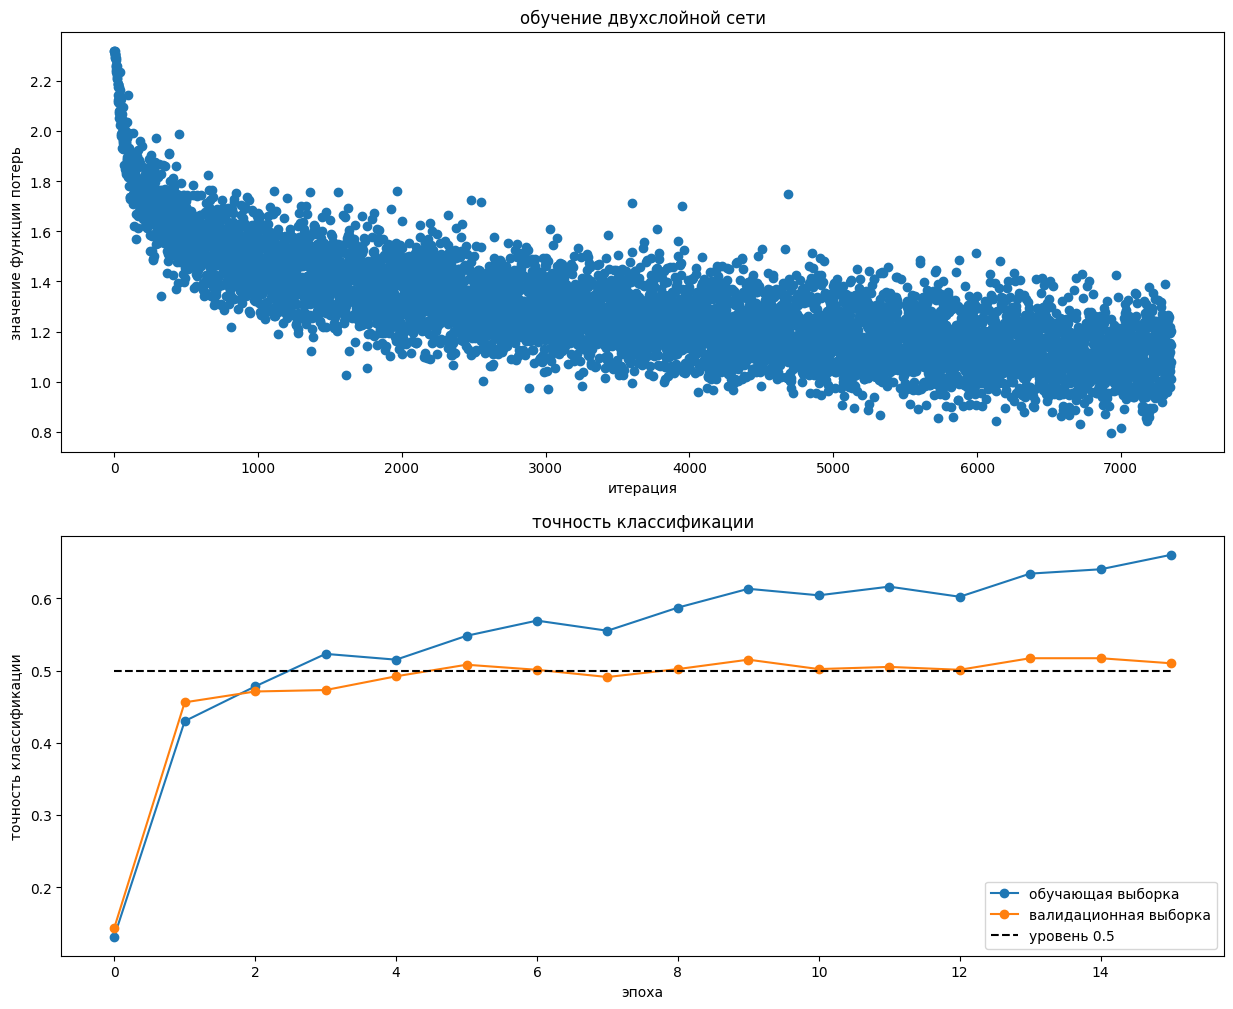

In [13]:
plt.subplot(2, 1, 1)
plt.title('обучение двухслойной сети')
plt.plot(solver.loss_history, 'o')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')

plt.subplot(2, 1, 2)
plt.title('точность классификации')
plt.plot(solver.train_acc_history, '-o', label='обучающая выборка')
plt.plot(solver.val_acc_history, '-o', label='валидационная выборка')
plt.plot([0.5] * len(solver.val_acc_history), 'k--', label='уровень 0.5')
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

Теперь реализуйте полносвязную сеть с произвольным числом скрытых слоев. Ознакомьтесь с классом FullyConnectedNet в scripts/classifiers/fc_net.py . Реализуйте инициализацию, прямой и обратный проходы.

In [14]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)
  
  # Most of the errors should be on the order of e-7 or smaller.   
  # NOTE: It is fine however to see an error for W2 on the order of e-5
  # for the check when reg = 0.0
  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Running check with reg =  0
Initial loss:  2.300479089758513
W1 relative error: 2.42e-07
W2 relative error: 2.26e-04
W3 relative error: 1.09e-07
b1 relative error: 7.59e-09
b2 relative error: 8.44e-10
b3 relative error: 8.54e-11
Running check with reg =  3.14
Initial loss:  7.052114776523025
W1 relative error: 9.73e-09
W2 relative error: 7.04e-08
W3 relative error: 3.48e-08
b1 relative error: 1.48e-08
b2 relative error: 1.79e-09
b3 relative error: 2.03e-10


Попробуйте добиться эффекта переобучения на небольшом наборе изображений (например, 50). Используйте трехслойную сеть со 100 нейронами на каждом скрытом слое. Попробуйте переобучить сеть, достигнув 100 % accuracy за 20 эпох. Для этого поэкспериментируйте с параметрами weight_scale и learning_rate. 

итерация 1 из 40 loss 20.998182
эпоха 0 из 20 точность train 0.12 точность val 0.122
эпоха 1 из 20 точность train 0.24 точность val 0.136
эпоха 2 из 20 точность train 0.46 точность val 0.145
эпоха 3 из 20 точность train 0.64 точность val 0.159
эпоха 4 из 20 точность train 0.74 точность val 0.169
эпоха 5 из 20 точность train 0.88 точность val 0.173
итерация 11 из 40 loss 0.072419
эпоха 6 из 20 точность train 0.86 точность val 0.166
эпоха 7 из 20 точность train 0.92 точность val 0.166
эпоха 8 из 20 точность train 0.98 точность val 0.164
эпоха 9 из 20 точность train 0.98 точность val 0.165
эпоха 10 из 20 точность train 0.98 точность val 0.162
итерация 21 из 40 loss 0.402236
эпоха 11 из 20 точность train 0.98 точность val 0.16
эпоха 12 из 20 точность train 1.0 точность val 0.157
эпоха 13 из 20 точность train 1.0 точность val 0.156
эпоха 14 из 20 точность train 1.0 точность val 0.156
эпоха 15 из 20 точность train 1.0 точность val 0.157
итерация 31 из 40 loss 0.007856
эпоха 16 из 20 точность

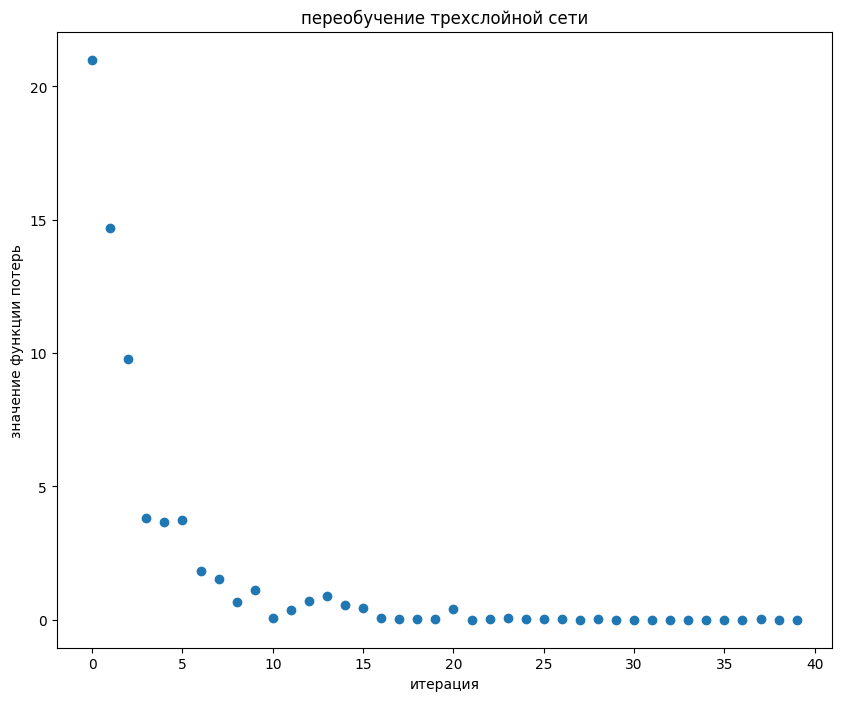

In [15]:
# TODO: Use a three-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 4e-2
learning_rate = 1e-3

model = FullyConnectedNet(
    [100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)

solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule='sgd',
    optim_config={
        'learning_rate': learning_rate
    }
)

solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('переобучение трехслойной сети')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')
plt.show()

Повторите эксперимент, описанный выше, для пятислойной сети.

итерация 1 из 40 loss 27.629925
эпоха 0 из 20 точность train 0.22 точность val 0.116
эпоха 1 из 20 точность train 0.24 точность val 0.083
эпоха 2 из 20 точность train 0.16 точность val 0.104
эпоха 3 из 20 точность train 0.52 точность val 0.106
эпоха 4 из 20 точность train 0.7 точность val 0.131
эпоха 5 из 20 точность train 0.7 точность val 0.116
итерация 11 из 40 loss 3.782508
эпоха 6 из 20 точность train 0.84 точность val 0.114
эпоха 7 из 20 точность train 0.88 точность val 0.108
эпоха 8 из 20 точность train 0.9 точность val 0.109
эпоха 9 из 20 точность train 0.96 точность val 0.114
эпоха 10 из 20 точность train 0.98 точность val 0.127
итерация 21 из 40 loss 0.261098
эпоха 11 из 20 точность train 1.0 точность val 0.126
эпоха 12 из 20 точность train 1.0 точность val 0.124
эпоха 13 из 20 точность train 1.0 точность val 0.124
эпоха 14 из 20 точность train 1.0 точность val 0.124
эпоха 15 из 20 точность train 1.0 точность val 0.125
итерация 31 из 40 loss 0.000594
эпоха 16 из 20 точность tr

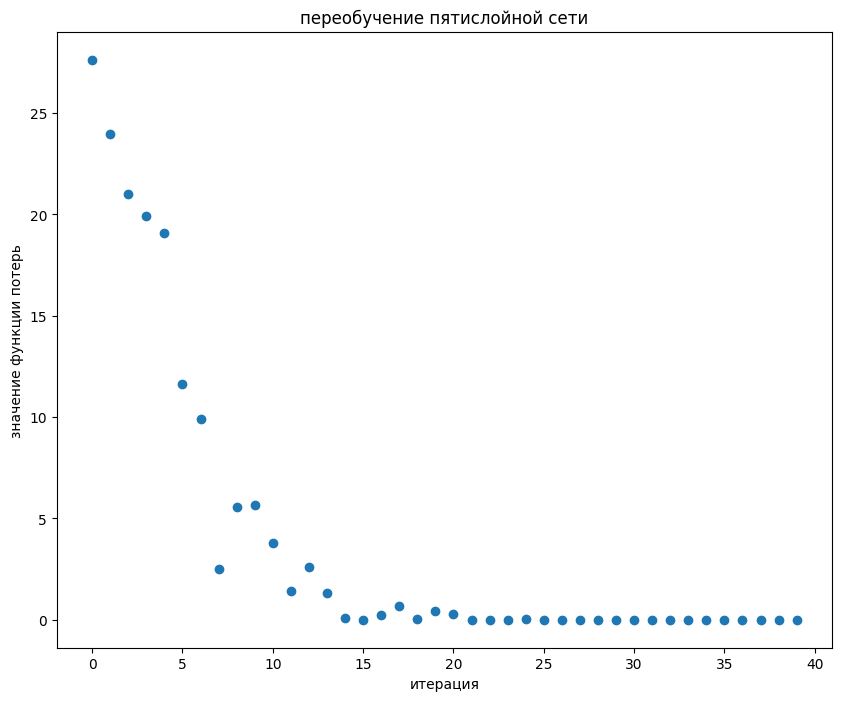

In [16]:
# TODO: Use a five-layer Net to overfit 50 training examples by
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

learning_rate = 1e-3
weight_scale = 1e-1

model = FullyConnectedNet(
    [100, 100, 100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)

solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule='sgd',
    optim_config={
        'learning_rate': learning_rate
    }
)

solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('переобучение пятислойной сети')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')
plt.show()

Сделайте выводы по проведенному эксперименту.

при работе на небольшой выборке обе сети способны почти полностью запомнить обучающие изображения. пятислойную сеть настраивать сложнее, так как увеличение глубины делает результат сильнее зависимым от масштаба начальных весов и скорости обучения.


Ранее обновление весов проходило по правилу SGD. Теперь попробуйте реализовать стохастический градиентный спуск с импульсом (SGD+momentum). http://cs231n.github.io/neural-networks-3/#sgd Реализуйте sgd_momentum в scripts/optim.py  и запустите проверку. 

In [17]:
from scripts.optim import sgd_momentum

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-3, 'velocity': v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Should see relative errors around e-8 or less
print('next_w error: ', rel_error(next_w, expected_next_w))
print('velocity error: ', rel_error(expected_velocity, config['velocity']))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


Сравните результаты обучения шестислойной сети, обученной классическим градиентным спуском и адаптивным алгоритмом с импульсом. Какой алгоритм сходится быстрее.

алгоритм sgd
итерация 1 из 200 loss 2.559978
эпоха 0 из 5 точность train 0.098 точность val 0.107
итерация 11 из 200 loss 2.238546
итерация 21 из 200 loss 2.168491
итерация 31 из 200 loss 2.261897
эпоха 1 из 5 точность train 0.247 точность val 0.217
итерация 41 из 200 loss 2.059339
итерация 51 из 200 loss 2.035495
итерация 61 из 200 loss 2.22338
итерация 71 из 200 loss 2.027476
эпоха 2 из 5 точность train 0.287 точность val 0.276
итерация 81 из 200 loss 2.034294
итерация 91 из 200 loss 1.979602
итерация 101 из 200 loss 2.062346
итерация 111 из 200 loss 1.958971
эпоха 3 из 5 точность train 0.303 точность val 0.285
итерация 121 из 200 loss 1.866778
итерация 131 из 200 loss 1.982992
итерация 141 из 200 loss 1.865054
итерация 151 из 200 loss 1.824595
эпоха 4 из 5 точность train 0.336 точность val 0.318
итерация 161 из 200 loss 1.877545
итерация 171 из 200 loss 1.687308
итерация 181 из 200 loss 1.756436
итерация 191 из 200 loss 1.81126
эпоха 5 из 5 точность train 0.389 точность val 0.312

а

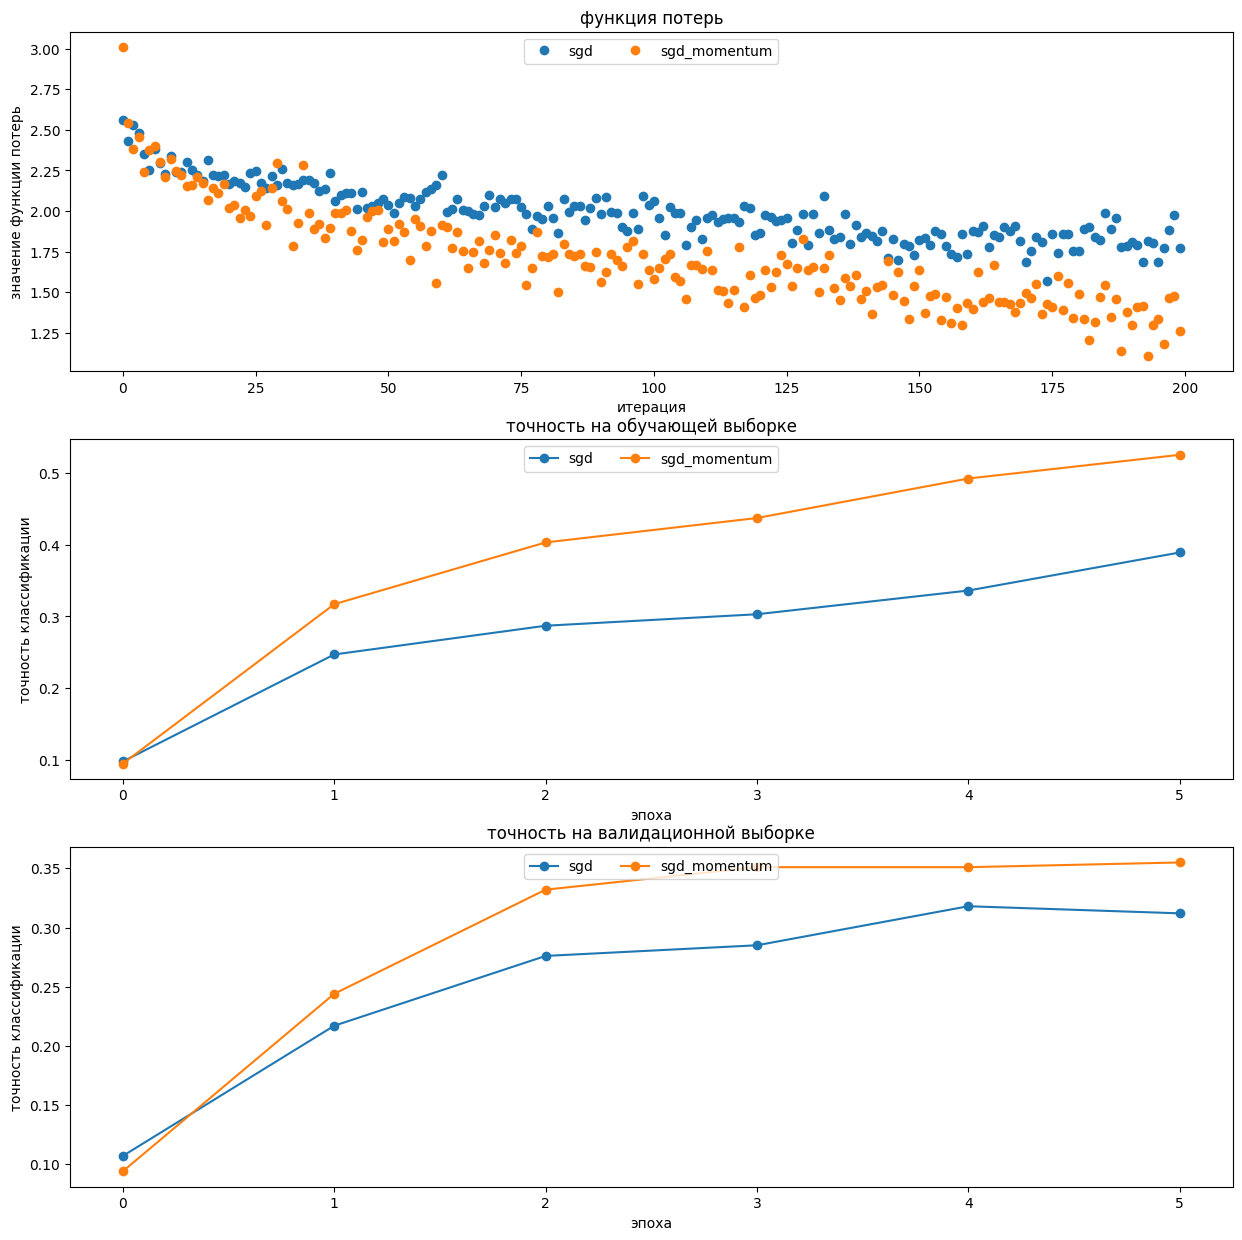

In [18]:
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
  print('алгоритм', update_rule)

  model = FullyConnectedNet(
      [100, 100, 100, 100, 100],
      weight_scale=5e-2
  )

  solver = Solver(
      model,
      small_data,
      num_epochs=5,
      batch_size=100,
      update_rule=update_rule,
      optim_config={
          'learning_rate': 5e-3
      },
      verbose=True
  )

  solvers[update_rule] = solver
  solver.train()
  print()

plt.subplot(3, 1, 1)
plt.title('функция потерь')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')

plt.subplot(3, 1, 2)
plt.title('точность на обучающей выборке')
plt.xlabel('эпоха')
plt.ylabel('точность классификации')

plt.subplot(3, 1, 3)
plt.title('точность на валидационной выборке')
plt.xlabel('эпоха')
plt.ylabel('точность классификации')

for update_rule, solver in solvers.items():
  plt.subplot(3, 1, 1)
  plt.plot(solver.loss_history, 'o', label=update_rule)

  plt.subplot(3, 1, 2)
  plt.plot(solver.train_acc_history, '-o', label=update_rule)

  plt.subplot(3, 1, 3)
  plt.plot(solver.val_acc_history, '-o', label=update_rule)

for i in [1, 2, 3]:
  plt.subplot(3, 1, i)
  plt.legend(loc='upper center', ncol=2)

plt.gcf().set_size_inches(15, 15)
plt.show()

Реализуйте алгоритмы RMSProp [1] and Adam [2] с коррекцией смещения  - методы rmsprop и adam . 


[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

In [19]:
# Test RMSProp implementation
from scripts.optim import rmsprop

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('cache error: ', rel_error(expected_cache, config['cache']))

next_w error:  9.524687511038133e-08
cache error:  2.6477955807156126e-09


In [20]:
# Test Adam implementation
from scripts.optim import adam

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('v error: ', rel_error(expected_v, config['v']))
print('m error: ', rel_error(expected_m, config['m']))

next_w error:  1.1395691798535431e-07
v error:  4.208314038113071e-09
m error:  4.214963193114416e-09


Обучите пару глубоких сетей с испольованием RMSProp и Adam алгоритмов обновления весов и сравните результаты обучения.

Получите лучшую полносвязную сеть для классификации вашего набора данных. На наборе CIFAR-10 необходимо получить accuracy не ниже 50 % на валидационном наборе.

In [21]:
best_model = None
################################################################################
# TODO: Train the best FullyConnectedNet that you can on CIFAR-10. You might   #
# find batch/layer normalization and dropout useful. Store your best model in  #
# the best_model variable.                                                     #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

best_model = FullyConnectedNet(
    [512, 256, 128],
    normalization='batchnorm',
    dropout=0.8,
    weight_scale=2e-2,
    reg=1e-3
)

best_solver = Solver(
    best_model,
    data,
    update_rule='adam',
    optim_config={
        'learning_rate': 1e-3
    },
    lr_decay=0.95,
    num_epochs=15,
    batch_size=200,
    print_every=200,
    verbose=True
)

best_solver.train()
best_model = best_solver.model

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                              END OF YOUR CODE                                #
################################################################################

итерация 1 из 3675 loss 2.665954
эпоха 0 из 15 точность train 0.182 точность val 0.203
итерация 201 из 3675 loss 1.843967
эпоха 1 из 15 точность train 0.491 точность val 0.465
итерация 401 из 3675 loss 1.725675
эпоха 2 из 15 точность train 0.475 точность val 0.491
итерация 601 из 3675 loss 1.60895
эпоха 3 из 15 точность train 0.509 точность val 0.531
итерация 801 из 3675 loss 1.567478
эпоха 4 из 15 точность train 0.553 точность val 0.528
итерация 1001 из 3675 loss 1.522823
итерация 1201 из 3675 loss 1.545865
эпоха 5 из 15 точность train 0.559 точность val 0.533
итерация 1401 из 3675 loss 1.5566
эпоха 6 из 15 точность train 0.561 точность val 0.538
итерация 1601 из 3675 loss 1.363539
эпоха 7 из 15 точность train 0.565 точность val 0.528
итерация 1801 из 3675 loss 1.374095
эпоха 8 из 15 точность train 0.568 точность val 0.556
итерация 2001 из 3675 loss 1.302193
итерация 2201 из 3675 loss 1.389209
эпоха 9 из 15 точность train 0.633 точность val 0.543
итерация 2401 из 3675 loss 1.410406
эп

Получите оценку accuracy для валидационной и тестовой выборок. 

In [22]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)

val_accuracy = (y_val_pred == data['y_val']).mean()
test_accuracy = (y_test_pred == data['y_test']).mean()

print('точность на валидационной выборке', val_accuracy)
print('точность на тестовой выборке', test_accuracy)

точность на валидационной выборке 0.588
точность на тестовой выборке 0.562


# Нормализация по мини-батчам

Идея нормализации по мини-батчам предложена в работе [1]

[1] Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift", ICML 2015.

Реализуйте прямой проход для слоя батч-нормализации - функция batchnorm_forward в scripts/layers.py . Проверьте свою реализацию, запустив следующий код:

In [23]:
# Check the training-time forward pass by checking means and variances
# of features both before and after batch normalization   

# Simulate the forward pass for a two-layer network
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before batch normalization:')
print_mean_std(a,axis=0)

gamma = np.ones((D3,))
beta = np.zeros((D3,))
# Means should be close to zero and stds close to one
print('After batch normalization (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])
# Now means should be close to beta and stds close to gamma
print('After batch normalization (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

Before batch normalization:
  means:  [ -2.3814598  -13.18038246   1.91780462]
  stds:   [27.18502186 34.21455511 37.68611762]

After batch normalization (gamma=1, beta=0)
  means:  [ 3.77475828e-17  6.16173779e-17 -3.42781359e-17]
  stds:   [0.99999999 1.         1.        ]

After batch normalization (gamma= [1. 2. 3.] , beta= [11. 12. 13.] )
  means:  [11. 12. 13.]
  stds:   [0.99999999 1.99999999 2.99999999]



In [24]:
# Check the test-time forward pass by running the training-time
# forward pass many times to warm up the running averages, and then
# checking the means and variances of activations after a test-time
# forward pass.

np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)

for t in range(50):
  X = np.random.randn(N, D1)
  a = np.maximum(0, X.dot(W1)).dot(W2)
  batchnorm_forward(a, gamma, beta, bn_param)

bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# Means should be close to zero and stds close to one, but will be
# noisier than training-time forward passes.
print('After batch normalization (test-time):')
print_mean_std(a_norm,axis=0)

After batch normalization (test-time):
  means:  [-0.03927354 -0.04349152 -0.10452688]
  stds:   [1.01531428 1.01238373 0.97819988]



Реализуйте обратный проход в функции batchnorm_backward.

In [25]:
# Gradient check batchnorm backward pass
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
#You should expect to see relative errors between 1e-13 and 1e-8
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  1.667461836271981e-09
dgamma error:  7.417225040694815e-13
dbeta error:  2.379446949959628e-12


Измените реализацию класса FullyConnectedNet, добавив батч-нормализацию. 
Если флаг normalization == "batchnorm", то вам необходимо вставить слой батч-нормализации перед каждым слоем активации ReLU, кроме выхода сети. 

In [26]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

# You should expect losses between 1e-4~1e-10 for W, 
# losses between 1e-08~1e-10 for b,
# and losses between 1e-08~1e-09 for beta and gammas.
for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64,
                            normalization='batchnorm')

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  if reg == 0: print()

Running check with reg =  0
Initial loss:  2.261195510124443
W1 relative error: 1.10e-04
W2 relative error: 4.70e-06
W3 relative error: 3.75e-10
b1 relative error: 3.11e-07
b2 relative error: 2.72e-07
b3 relative error: 1.01e-10
beta1 relative error: 1.77e-08
beta2 relative error: 2.40e-09
gamma1 relative error: 6.96e-09
gamma2 relative error: 2.41e-09

Running check with reg =  3.14
Initial loss:  6.996533220098718
W1 relative error: 1.98e-06
W2 relative error: 2.28e-06
W3 relative error: 5.60e-09
b1 relative error: 1.38e-08
b2 relative error: 7.99e-07
b3 relative error: 1.72e-10
beta1 relative error: 6.65e-09
beta2 relative error: 3.48e-09
gamma1 relative error: 6.27e-09
gamma2 relative error: 5.28e-09


Обучите 6-ти слойную сеть на наборе из 1000 изображений с батч-нормализацией и без нее

In [27]:
np.random.seed(231)
# Try training a very deep net with batchnorm
hidden_dims = [100, 100, 100, 100, 100]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 2e-2
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

print('Solver with batch norm:')
bn_solver = Solver(bn_model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True,print_every=20)
bn_solver.train()

print('\nSolver without batch norm:')
solver = Solver(model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20)
solver.train()

Solver with batch norm:
итерация 1 из 200 loss 2.340974
эпоха 0 из 10 точность train 0.107 точность val 0.115
эпоха 1 из 10 точность train 0.315 точность val 0.267
итерация 21 из 200 loss 2.039365
эпоха 2 из 10 точность train 0.384 точность val 0.28
итерация 41 из 200 loss 2.041102
эпоха 3 из 10 точность train 0.494 точность val 0.309
итерация 61 из 200 loss 1.753902
эпоха 4 из 10 точность train 0.533 точность val 0.307
итерация 81 из 200 loss 1.246584
эпоха 5 из 10 точность train 0.575 точность val 0.314
итерация 101 из 200 loss 1.322833
эпоха 6 из 10 точность train 0.641 точность val 0.335
итерация 121 из 200 loss 1.121864
эпоха 7 из 10 точность train 0.7 точность val 0.329
итерация 141 из 200 loss 1.148365
эпоха 8 из 10 точность train 0.734 точность val 0.321
итерация 161 из 200 loss 0.661473
эпоха 9 из 10 точность train 0.791 точность val 0.346
итерация 181 из 200 loss 0.872029
эпоха 10 из 10 точность train 0.78 точность val 0.326

Solver without batch norm:
итерация 1 из 200 loss 

Визуализируйте процесс обучения для двух сетей. Увеличилась ли скорость сходимости в случае с батч-нормализацией? Сделайте выводы.

при использовании batch normalization обучение обычно становится более стабильным. по графикам можно сравнить скорость снижения функции потерь и рост точности. если кривые близки, это означает, что на выбранной небольшой выборке преимущество нормализации выражено слабо.


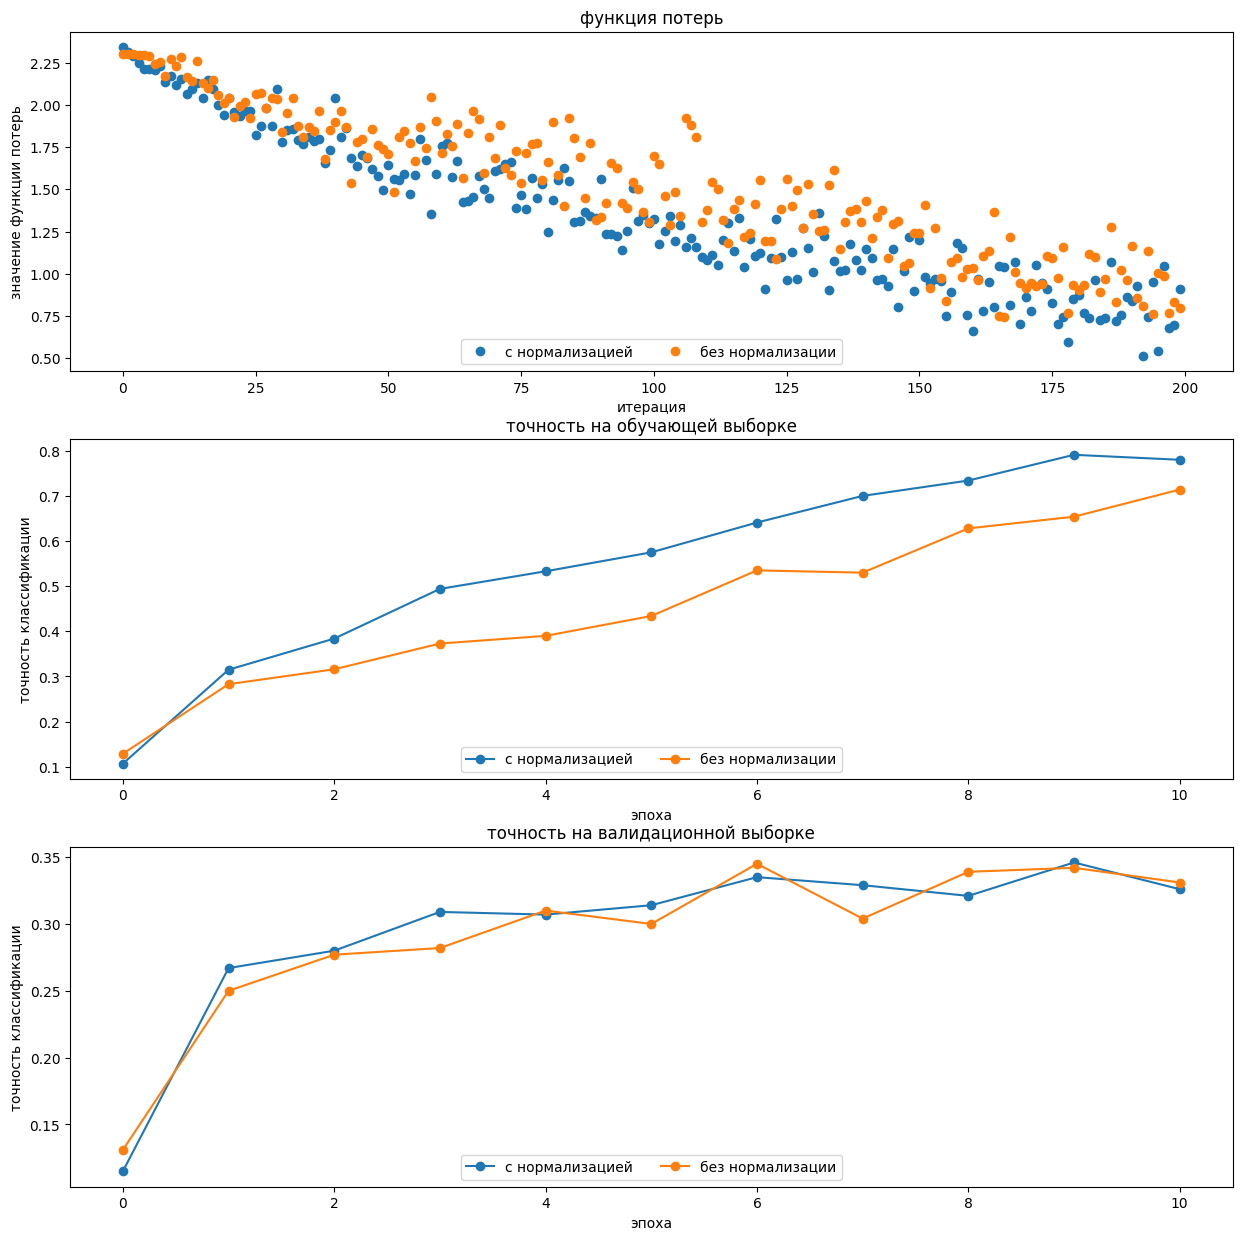

In [28]:
def plot_training_history(title, label, baseline, bn_solvers, plot_fn, bl_marker='.', bn_marker='.', labels=None):
    plt.title(title)
    plt.xlabel(label)

    bn_plots = [plot_fn(bn_solver) for bn_solver in bn_solvers]
    bl_plot = plot_fn(baseline)
    num_bn = len(bn_plots)

    for i in range(num_bn):
        current_label = 'с нормализацией'
        if labels is not None:
            current_label += ' ' + str(labels[i])
        plt.plot(bn_plots[i], bn_marker, label=current_label)

    current_label = 'без нормализации'
    if labels is not None:
        current_label += ' ' + str(labels[0])

    plt.plot(bl_plot, bl_marker, label=current_label)
    plt.legend(loc='lower center', ncol=num_bn + 1)


plt.subplot(3, 1, 1)
plot_training_history(
    'функция потерь',
    'итерация',
    solver,
    [bn_solver],
    lambda x: x.loss_history,
    bl_marker='o',
    bn_marker='o'
)

plt.ylabel('значение функции потерь')

plt.subplot(3, 1, 2)
plot_training_history(
    'точность на обучающей выборке',
    'эпоха',
    solver,
    [bn_solver],
    lambda x: x.train_acc_history,
    bl_marker='-o',
    bn_marker='-o'
)

plt.ylabel('точность классификации')

plt.subplot(3, 1, 3)
plot_training_history(
    'точность на валидационной выборке',
    'эпоха',
    solver,
    [bn_solver],
    lambda x: x.val_acc_history,
    bl_marker='-o',
    bn_marker='-o'
)

plt.ylabel('точность классификации')
plt.gcf().set_size_inches(15, 15)
plt.show()

Обучите 6-тислойную сеть с батч-нормализацией и без нее, используя разные размеры батча. Визуализируйте графики обучения. Сделайте выводы по результатам эксперимента.

при маленьком размере мини батча оценки среднего и дисперсии получаются более шумными. при увеличении размера батча обучение обычно становится стабильнее, хотя слишком большой батч уменьшает число обновлений весов за одну эпоху.


In [29]:
def run_batchsize_experiments(normalization_mode):
    np.random.seed(231)
    # Try training a very deep net with batchnorm
    hidden_dims = [100, 100, 100, 100, 100]
    num_train = 1000
    small_data = {
      'X_train': data['X_train'][:num_train],
      'y_train': data['y_train'][:num_train],
      'X_val': data['X_val'],
      'y_val': data['y_val'],
    }
    n_epochs=10
    weight_scale = 2e-2
    batch_sizes = [5,10,50]
    lr = 10**(-3.5)
    solver_bsize = batch_sizes[0]

    print('No normalization: batch size = ',solver_bsize)
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)
    solver = Solver(model, small_data,
                    num_epochs=n_epochs, batch_size=solver_bsize,
                    update_rule='adam',
                    optim_config={
                      'learning_rate': lr,
                    },
                    verbose=False)
    solver.train()
    
    bn_solvers = []
    for i in range(len(batch_sizes)):
        b_size=batch_sizes[i]
        print('Normalization: batch size = ',b_size)
        bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=normalization_mode)
        bn_solver = Solver(bn_model, small_data,
                        num_epochs=n_epochs, batch_size=b_size,
                        update_rule='adam',
                        optim_config={
                          'learning_rate': lr,
                        },
                        verbose=False)
        bn_solver.train()
        bn_solvers.append(bn_solver)
        
    return bn_solvers, solver, batch_sizes

batch_sizes = [5,10,50]
bn_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('batchnorm')

No normalization: batch size =  5
Normalization: batch size =  5
Normalization: batch size =  10
Normalization: batch size =  50


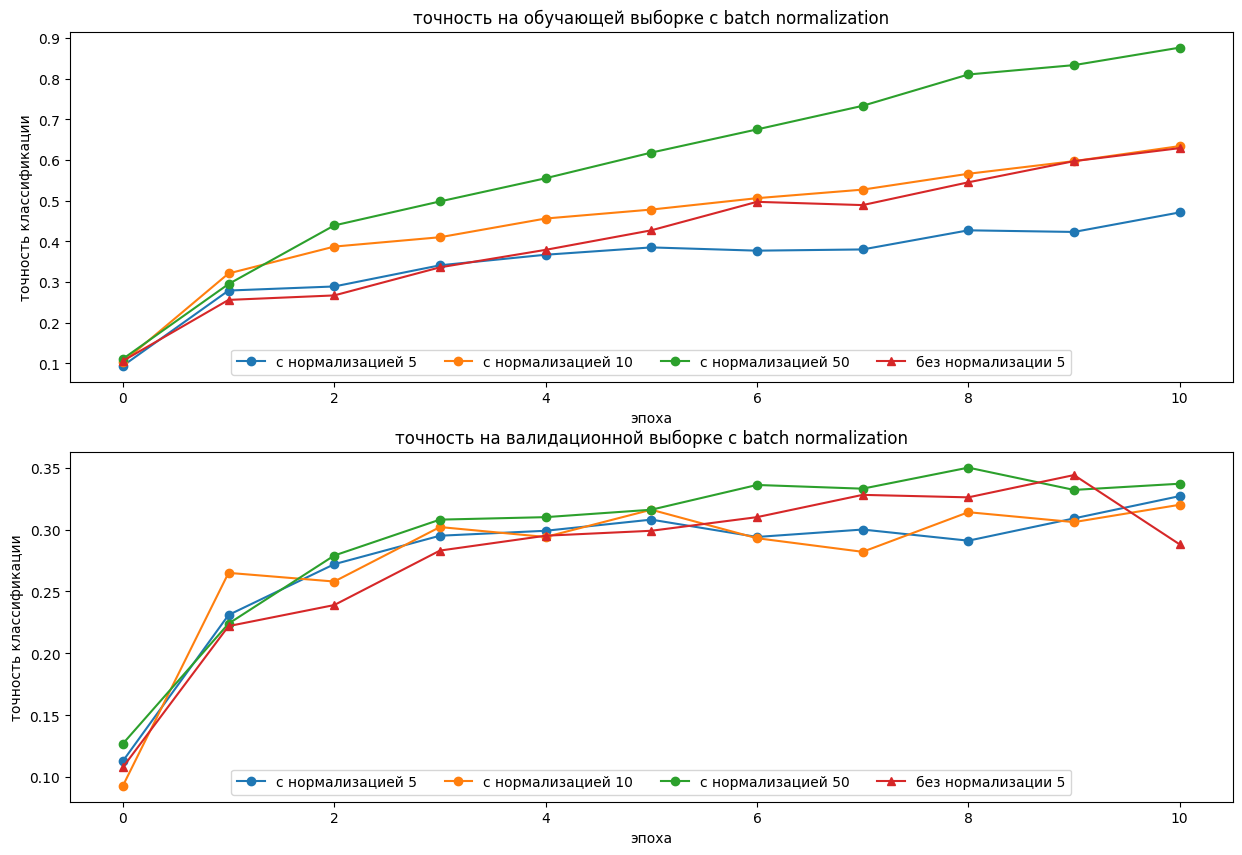

In [30]:
plt.subplot(2, 1, 1)
plot_training_history(
    'точность на обучающей выборке с batch normalization',
    'эпоха',
    solver_bsize,
    bn_solvers_bsize,
    lambda x: x.train_acc_history,
    bl_marker='-^',
    bn_marker='-o',
    labels=batch_sizes
)

plt.ylabel('точность классификации')

plt.subplot(2, 1, 2)
plot_training_history(
    'точность на валидационной выборке с batch normalization',
    'эпоха',
    solver_bsize,
    bn_solvers_bsize,
    lambda x: x.val_acc_history,
    bl_marker='-^',
    bn_marker='-o',
    labels=batch_sizes
)

plt.ylabel('точность классификации')
plt.gcf().set_size_inches(15, 10)
plt.show()

# Dropout

Реализуйте прямой проход для dropout-слоя в scripts/layers.py

http://cs231n.github.io/neural-networks-2/#reg

In [31]:
np.random.seed(231)
x = np.random.randn(500, 500) + 10

for p in [0.25, 0.4, 0.7]:
  out, _ = dropout_forward(x, {'mode': 'train', 'p': p})
  out_test, _ = dropout_forward(x, {'mode': 'test', 'p': p})

  print('Running tests with p = ', p)
  print('Mean of input: ', x.mean())
  print('Mean of train-time output: ', out.mean())
  print('Mean of test-time output: ', out_test.mean())
  print('Fraction of train-time output set to zero: ', (out == 0).mean())
  print('Fraction of test-time output set to zero: ', (out_test == 0).mean())
  print()

Running tests with p =  0.25
Mean of input:  10.0002078784775
Mean of train-time output:  10.014059116977283
Mean of test-time output:  10.0002078784775
Fraction of train-time output set to zero:  0.749784
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.4
Mean of input:  10.0002078784775
Mean of train-time output:  9.977917658761159
Mean of test-time output:  10.0002078784775
Fraction of train-time output set to zero:  0.600796
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.7
Mean of input:  10.0002078784775
Mean of train-time output:  9.987811912159428
Mean of test-time output:  10.0002078784775
Fraction of train-time output set to zero:  0.30074
Fraction of test-time output set to zero:  0.0



Реализуйте обратный проход для dropout-слоя

In [32]:
np.random.seed(231)
x = np.random.randn(10, 10) + 10
dout = np.random.randn(*x.shape)

dropout_param = {'mode': 'train', 'p': 0.2, 'seed': 123}
out, cache = dropout_forward(x, dropout_param)
dx = dropout_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda xx: dropout_forward(xx, dropout_param)[0], x, dout)

# Error should be around e-10 or less
print('dx relative error: ', rel_error(dx, dx_num))

dx relative error:  5.44560814873387e-11


Добавьте в реализацию класса FullyConnectedNet поддержку dropout. Если параметр dropout != 1, то добавьте в модель dropout-слой после каждого слоя активации. Проверьте свою реализацию

In [33]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for dropout in [1, 0.75, 0.5]:
  print('Running check with dropout = ', dropout)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            weight_scale=5e-2, dtype=np.float64,
                            dropout=dropout, seed=123)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)
  
  # Relative errors should be around e-6 or less; Note that it's fine
  # if for dropout=1 you have W2 error be on the order of e-5.
  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  print()

Running check with dropout =  1
Initial loss:  2.300479089758513
W1 relative error: 2.42e-07
W2 relative error: 2.26e-04
W3 relative error: 1.09e-07
b1 relative error: 7.59e-09
b2 relative error: 8.44e-10
b3 relative error: 8.54e-11

Running check with dropout =  0.75
Initial loss:  2.302371489694414
W1 relative error: 1.85e-07
W2 relative error: 1.30e-06
W3 relative error: 3.31e-08
b1 relative error: 2.19e-09
b2 relative error: 1.82e-09
b3 relative error: 1.20e-10

Running check with dropout =  0.5
Initial loss:  2.3042759220685727
W1 relative error: 1.20e-06
W2 relative error: 5.18e-08
W3 relative error: 6.43e-08
b1 relative error: 5.37e-09
b2 relative error: 2.99e-09
b3 relative error: 7.36e-11



Обучите две двухслойные сети с dropout-слоем (вероятность отсева 0,25) и без на наборе из 500 изображений. Визуализируйте графики обучения. Сделайте выводы по результатам эксперимента

dropout уменьшает возможность сети просто запомнить обучающую выборку. поэтому точность на обучающих данных может расти медленнее, а разница между обучающей и валидационной точностью обычно становится меньше. на маленьком наборе из 500 изображений результат может заметно колебаться от запуска к запуску.


In [34]:
# Train two identical nets, one with dropout and one without
np.random.seed(231)
num_train = 500
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}
dropout_choices = [1, 0.25]
for dropout in dropout_choices:
  model = FullyConnectedNet([500], dropout=dropout)
  print(dropout)

  solver = Solver(model, small_data,
                  num_epochs=25, batch_size=100,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 5e-4,
                  },
                  verbose=True, print_every=100)
  solver.train()
  solvers[dropout] = solver
  print()

1
итерация 1 из 125 loss 7.856204
эпоха 0 из 25 точность train 0.26 точность val 0.184
эпоха 1 из 25 точность train 0.416 точность val 0.258
эпоха 2 из 25 точность train 0.482 точность val 0.276
эпоха 3 из 25 точность train 0.532 точность val 0.277
эпоха 4 из 25 точность train 0.6 точность val 0.271
эпоха 5 из 25 точность train 0.708 точность val 0.299
эпоха 6 из 25 точность train 0.722 точность val 0.282
эпоха 7 из 25 точность train 0.832 точность val 0.255
эпоха 8 из 25 точность train 0.88 точность val 0.268
эпоха 9 из 25 точность train 0.902 точность val 0.277
эпоха 10 из 25 точность train 0.898 точность val 0.261
эпоха 11 из 25 точность train 0.924 точность val 0.263
эпоха 12 из 25 точность train 0.96 точность val 0.3
эпоха 13 из 25 точность train 0.972 точность val 0.315
эпоха 14 из 25 точность train 0.972 точность val 0.311
эпоха 15 из 25 точность train 0.972 точность val 0.317
эпоха 16 из 25 точность train 0.994 точность val 0.309
эпоха 17 из 25 точность train 0.974 точность val

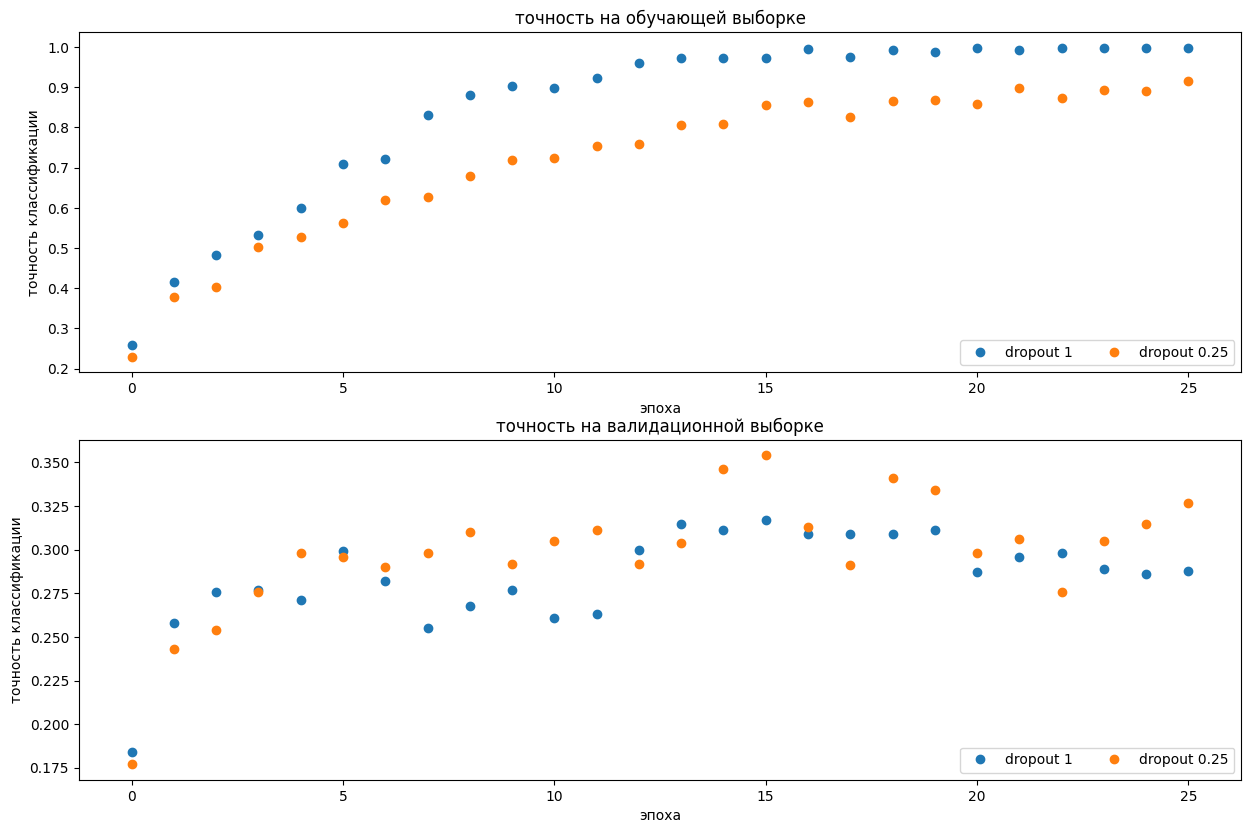

In [35]:
train_accs = []
val_accs = []

for dropout in dropout_choices:
  solver = solvers[dropout]
  train_accs.append(solver.train_acc_history[-1])
  val_accs.append(solver.val_acc_history[-1])

plt.subplot(3, 1, 1)

for dropout in dropout_choices:
  plt.plot(
      solvers[dropout].train_acc_history,
      'o',
      label='dropout ' + str(dropout)
  )

plt.title('точность на обучающей выборке')
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.legend(ncol=2, loc='lower right')

plt.subplot(3, 1, 2)

for dropout in dropout_choices:
  plt.plot(
      solvers[dropout].val_acc_history,
      'o',
      label='dropout ' + str(dropout)
  )

plt.title('точность на валидационной выборке')
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.legend(ncol=2, loc='lower right')

plt.gcf().set_size_inches(15, 15)
plt.show()

# Сверточные нейронные сети (CNN)

Реализуйте прямой проход для сверточного слоя - функция conv_forward_naive в scripts/layers.py юПроверьте свою реализацию, запустив код ниже 

In [36]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)
x = np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)
w = np.linspace(-0.2, 0.3, num=np.prod(w_shape)).reshape(w_shape)
b = np.linspace(-0.1, 0.2, num=3)

conv_param = {'stride': 2, 'pad': 1}
out, _ = conv_forward_naive(x, w, b, conv_param)
correct_out = np.array([[[[-0.08759809, -0.10987781],
                           [-0.18387192, -0.2109216 ]],
                          [[ 0.21027089,  0.21661097],
                           [ 0.22847626,  0.23004637]],
                          [[ 0.50813986,  0.54309974],
                           [ 0.64082444,  0.67101435]]],
                         [[[-0.98053589, -1.03143541],
                           [-1.19128892, -1.24695841]],
                          [[ 0.69108355,  0.66880383],
                           [ 0.59480972,  0.56776003]],
                          [[ 2.36270298,  2.36904306],
                           [ 2.38090835,  2.38247847]]]])

# Compare your output to ours; difference should be around e-8
print('Testing conv_forward_naive')
print('difference: ', rel_error(out, correct_out))

Testing conv_forward_naive
difference:  2.2121476417505994e-08


Реализуйте обратный проход - функция conv_backward_naive в scripts/layers.py

In [37]:
np.random.seed(231)
x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(2,)
dout = np.random.randn(4, 2, 5, 5)
conv_param = {'stride': 1, 'pad': 1}

dx_num = eval_numerical_gradient_array(lambda x: conv_forward_naive(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_forward_naive(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_forward_naive(x, w, b, conv_param)[0], b, dout)

out, cache = conv_forward_naive(x, w, b, conv_param)
dx, dw, db = conv_backward_naive(dout, cache)

# Your errors should be around e-8 or less.
print('Testing conv_backward_naive function')
print('dx error: ', rel_error(dx, dx_num))
print('dw error: ', rel_error(dw, dw_num))
print('db error: ', rel_error(db, db_num))

Testing conv_backward_naive function
dx error:  1.159803161159293e-08
dw error:  2.2471264748452487e-10
db error:  3.37264006649648e-11


Реализуйте прямой проход для max-pooling слоя -функция  max_pool_forward_naive в scripts/layers.py

In [38]:
x_shape = (2, 3, 4, 4)
x = np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)
pool_param = {'pool_width': 2, 'pool_height': 2, 'stride': 2}

out, _ = max_pool_forward_naive(x, pool_param)

correct_out = np.array([[[[-0.26315789, -0.24842105],
                          [-0.20421053, -0.18947368]],
                         [[-0.14526316, -0.13052632],
                          [-0.08631579, -0.07157895]],
                         [[-0.02736842, -0.01263158],
                          [ 0.03157895,  0.04631579]]],
                        [[[ 0.09052632,  0.10526316],
                          [ 0.14947368,  0.16421053]],
                         [[ 0.20842105,  0.22315789],
                          [ 0.26736842,  0.28210526]],
                         [[ 0.32631579,  0.34105263],
                          [ 0.38526316,  0.4       ]]]])

# Compare your output with ours. Difference should be on the order of e-8.
print('Testing max_pool_forward_naive function:')
print('difference: ', rel_error(out, correct_out))

Testing max_pool_forward_naive function:
difference:  4.1666665157267834e-08


Реализуйте обратный проход для max-pooling слоя в max_pool_backward_naive . 

In [39]:
np.random.seed(231)
x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

dx_num = eval_numerical_gradient_array(lambda x: max_pool_forward_naive(x, pool_param)[0], x, dout)

out, cache = max_pool_forward_naive(x, pool_param)
dx = max_pool_backward_naive(dout, cache)

# Your error should be on the order of e-12
print('Testing max_pool_backward_naive function:')
print('dx error: ', rel_error(dx, dx_num))

Testing max_pool_backward_naive function:
dx error:  3.27562514223145e-12


В скрипте scripts/fast_layers.py представлены быстрые реализации слоев свертки и пуллинга, написанных с использованием  Cython. 

Для компиляции выполните следующую команду в директории scripts

```bash
python setup.py build_ext --inplace
```

в подготовленных скриптах быстрая версия свертки реализована на numpy через преобразование im2col, поэтому отдельная компиляция cython для запуска этой работы не требуется.


Сравните ваши реализации слоев свертки и пуллинга с быстрыми реализациями.

In [40]:
# Rel errors should be around e-9 or less
from scripts.fast_layers import conv_forward_fast, conv_backward_fast
from time import time
np.random.seed(231)
x = np.random.randn(100, 3, 31, 31)
w = np.random.randn(25, 3, 3, 3)
b = np.random.randn(25,)
dout = np.random.randn(100, 25, 16, 16)
conv_param = {'stride': 2, 'pad': 1}

t0 = time()
out_naive, cache_naive = conv_forward_naive(x, w, b, conv_param)
t1 = time()
out_fast, cache_fast = conv_forward_fast(x, w, b, conv_param)
t2 = time()

print('Testing conv_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('Difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive, dw_naive, db_naive = conv_backward_naive(dout, cache_naive)
t1 = time()
dx_fast, dw_fast, db_fast = conv_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting conv_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))
print('dw difference: ', rel_error(dw_naive, dw_fast))
print('db difference: ', rel_error(db_naive, db_fast))

Testing conv_forward_fast:
Naive: 2.822102s
Fast: 0.005229s
Speedup: 539.653187x
Difference:  4.926407851494105e-11

Testing conv_backward_fast:
Naive: 3.943095s
Fast: 0.013306s
Speedup: 296.347137x
dx difference:  1.949764775345631e-11
dw difference:  6.002352825341133e-13
db difference:  0.0


In [41]:
# Relative errors should be close to 0.0
from scripts.fast_layers import max_pool_forward_fast, max_pool_backward_fast
np.random.seed(231)
x = np.random.randn(100, 3, 32, 32)
dout = np.random.randn(100, 3, 16, 16)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

t0 = time()
out_naive, cache_naive = max_pool_forward_naive(x, pool_param)
t1 = time()
out_fast, cache_fast = max_pool_forward_fast(x, pool_param)
t2 = time()

print('Testing pool_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('fast: %fs' % (t2 - t1))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive = max_pool_backward_naive(dout, cache_naive)
t1 = time()
dx_fast = max_pool_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting pool_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('fast: %fs' % (t2 - t1))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))

Testing pool_forward_fast:
Naive: 0.222607s
fast: 0.003670s
speedup: 60.652267x
difference:  0.0

Testing pool_backward_fast:
Naive: 0.617493s
fast: 0.007106s
speedup: 86.899544x
dx difference:  0.0


В layer_utils.py вы можете найти  часто используемые комбинации слоев, используемых в сверточных сетях. Ознакомьтесь с ними и запустите код ниже для проверки их работы

In [42]:
from scripts.layer_utils import conv_relu_pool_forward, conv_relu_pool_backward
np.random.seed(231)
x = np.random.randn(2, 3, 16, 16)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

out, cache = conv_relu_pool_forward(x, w, b, conv_param, pool_param)
dx, dw, db = conv_relu_pool_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], b, dout)

# Relative errors should be around e-8 or less
print('Testing conv_relu_pool')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu_pool
dx error:  9.591132621921372e-09
dw error:  5.802428657473038e-09
db error:  3.57960501324485e-10


In [43]:
from scripts.layer_utils import conv_relu_forward, conv_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 8, 8)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}

out, cache = conv_relu_forward(x, w, b, conv_param)
dx, dw, db = conv_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_forward(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_forward(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_forward(x, w, b, conv_param)[0], b, dout)

# Relative errors should be around e-8 or less
print('Testing conv_relu:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu:
dx error:  1.5218619980349303e-09
dw error:  3.371590129777511e-10
db error:  4.8422803898140394e-11


Напишите реализацию класса ThreeLayerConvNet в scripts/classifiers/cnn.py . Вы можете использовать готовые реализации слоев и их комбинаций.

Проверьте вашу реализацию. Ожидается, что значение функции потерь softmax будет порядка `log(C)` для `C` классов для случая без регуляризации. В случае регуляризации значение функции потерь должно немного возрасти. 

In [44]:
model = ThreeLayerConvNet()

N = 50
X = np.random.randn(N, 3, 32, 32)
y = np.random.randint(10, size=N)

loss, grads = model.loss(X, y)
print('Initial loss (no regularization): ', loss)

model.reg = 0.5
loss, grads = model.loss(X, y)
print('Initial loss (with regularization): ', loss)

Initial loss (no regularization):  2.3025860712339874
Initial loss (with regularization):  2.508255623321771


Проверьте реализацию обратного прохода

In [45]:
num_inputs = 2
input_dim = (3, 16, 16)
reg = 0.0
num_classes = 10
np.random.seed(231)
X = np.random.randn(num_inputs, *input_dim)
y = np.random.randint(num_classes, size=num_inputs)

model = ThreeLayerConvNet(num_filters=3, filter_size=3,
                          input_dim=input_dim, hidden_dim=7,
                          dtype=np.float64)
loss, grads = model.loss(X, y)
# Errors should be small, but correct implementations may have
# relative errors up to the order of e-2
for param_name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    param_grad_num = eval_numerical_gradient(f, model.params[param_name], verbose=False, h=1e-6)
    e = rel_error(param_grad_num, grads[param_name])
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W1 max relative error: 3.053965e-04
W2 max relative error: 1.822723e-02
W3 max relative error: 1.005197e-04
b1 max relative error: 3.477652e-05
b2 max relative error: 2.517459e-03
b3 max relative error: 1.212754e-09


Попробуйте добиться эффекта переобучения. Обучите модель на небольшом наборе данных.Сравните значения accuracy на обучающих данных и на валидационных. Визуализируйте графики обучения 

In [46]:
np.random.seed(231)

num_train = 100
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

model = ThreeLayerConvNet(weight_scale=1e-2)

solver = Solver(model, small_data,
                num_epochs=15, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=1)
solver.train()

итерация 1 из 30 loss 2.41406
эпоха 0 из 15 точность train 0.2 точность val 0.137
итерация 2 из 30 loss 3.102925
эпоха 1 из 15 точность train 0.14 точность val 0.087
итерация 3 из 30 loss 2.27033
итерация 4 из 30 loss 2.096705
эпоха 2 из 15 точность train 0.24 точность val 0.094
итерация 5 из 30 loss 1.83888
итерация 6 из 30 loss 1.934188
эпоха 3 из 15 точность train 0.51 точность val 0.173
итерация 7 из 30 loss 1.827912
итерация 8 из 30 loss 1.639574
эпоха 4 из 15 точность train 0.52 точность val 0.188
итерация 9 из 30 loss 1.330082
итерация 10 из 30 loss 1.756115
эпоха 5 из 15 точность train 0.63 точность val 0.167
итерация 11 из 30 loss 1.024162
итерация 12 из 30 loss 1.041826
эпоха 6 из 15 точность train 0.75 точность val 0.229
итерация 13 из 30 loss 1.142777
итерация 14 из 30 loss 0.835706
эпоха 7 из 15 точность train 0.79 точность val 0.247
итерация 15 из 30 loss 0.587786
итерация 16 из 30 loss 0.645509
эпоха 8 из 15 точность train 0.82 точность val 0.252
итерация 17 из 30 loss 0

In [47]:
# Print final training accuracy
print(
    "Small data training accuracy:",
    solver.check_accuracy(small_data['X_train'], small_data['y_train'])
)

Small data training accuracy: 0.82


In [48]:
# Print final validation accuracy
print(
    "Small data validation accuracy:",
    solver.check_accuracy(small_data['X_val'], small_data['y_val'])
)

Small data validation accuracy: 0.252


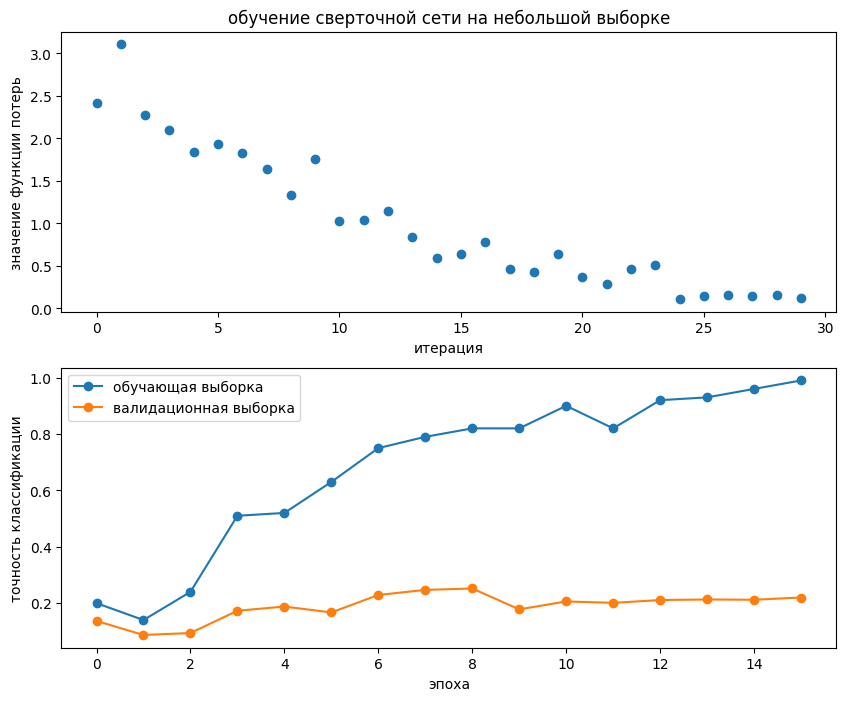

In [49]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, 'o')
plt.title('обучение сверточной сети на небольшой выборке')
plt.xlabel('итерация')
plt.ylabel('значение функции потерь')

plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, '-o')
plt.plot(solver.val_acc_history, '-o')
plt.legend(
    ['обучающая выборка', 'валидационная выборка'],
    loc='upper left'
)
plt.xlabel('эпоха')
plt.ylabel('точность классификации')
plt.show()

Обучите сеть на полном наборе данных. Выведите accuracy на обучающей и валидационной выборках

In [50]:
model = ThreeLayerConvNet(weight_scale=0.001, hidden_dim=500, reg=0.001)

solver = Solver(model, data,
                num_epochs=1, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20)
solver.train()

итерация 1 из 980 loss 2.30474
эпоха 0 из 1 точность train 0.084 точность val 0.107
итерация 21 из 980 loss 2.27023
итерация 41 из 980 loss 2.138312
итерация 61 из 980 loss 1.956392
итерация 81 из 980 loss 1.92014
итерация 101 из 980 loss 1.808227
итерация 121 из 980 loss 1.97845
итерация 141 из 980 loss 1.722642
итерация 161 из 980 loss 1.908407
итерация 181 из 980 loss 2.098066
итерация 201 из 980 loss 1.899736
итерация 221 из 980 loss 1.782479
итерация 241 из 980 loss 1.792844
итерация 261 из 980 loss 1.838123
итерация 281 из 980 loss 1.64661
итерация 301 из 980 loss 1.595531
итерация 321 из 980 loss 1.984281
итерация 341 из 980 loss 1.731628
итерация 361 из 980 loss 1.490279
итерация 381 из 980 loss 2.101654
итерация 401 из 980 loss 1.607589
итерация 421 из 980 loss 1.837586
итерация 441 из 980 loss 1.725196
итерация 461 из 980 loss 1.459242
итерация 481 из 980 loss 1.597933
итерация 501 из 980 loss 1.826296
итерация 521 из 980 loss 1.622415
итерация 541 из 980 loss 1.926995
итерац

In [51]:
# Print final training accuracy
print(
    "Full data training accuracy:",
    solver.check_accuracy(small_data['X_train'], small_data['y_train'])
)

Full data training accuracy: 0.37


In [52]:
# Print final validation accuracy
print(
    "Full data validation accuracy:",
    solver.check_accuracy(data['X_val'], data['y_val'])
)

Full data validation accuracy: 0.48


Визуализируйте фильтры на первом слое обученной сети

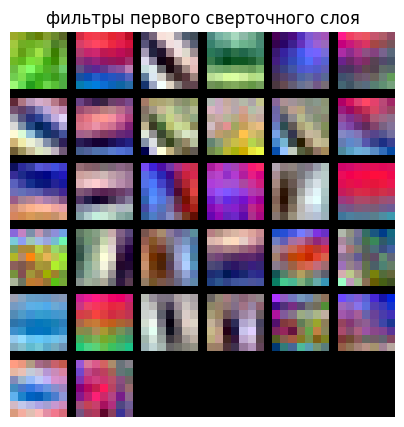

In [53]:
from scripts.vis_utils import visualize_grid

grid = visualize_grid(model.params['W1'].transpose(0, 2, 3, 1))

plt.imshow(grid.astype('uint8'))
plt.title('фильтры первого сверточного слоя')
plt.axis('off')
plt.gcf().set_size_inches(5, 5)
plt.show()